In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Location of our PlantVillage dataset

data_path = Path(
    r"C:\Users\ABHAY YADAV\OneDrive\Desktop\ghub\plan leaf disease system\Dataset\plantvillage dataset"
)

# Check whether the path exists
if data_path.exists():
    print("Dataset found successfully!")

    print("\nFolders available inside the dataset:")

    for folder in data_path.iterdir():
        if folder.is_dir():
            print("-", folder.name)

else:
    print("Dataset not found. Please check the path.")

Dataset found successfully!

Folders available inside the dataset:
- color
- grayscale
- segmented


In [3]:
# Get all class folders
class_folders = [
    folder for folder in data_path.iterdir()
    if folder.is_dir()
]

print("Total number of categories:", len(class_folders))

print("\nAvailable categories:\n")

for i, folder in enumerate(class_folders, start=1):
    print(f"{i}. {folder.name}")

Total number of categories: 3

Available categories:

1. color
2. grayscale
3. segmented


In [4]:
# Select the color dataset
color_path = data_path / "color"

# Display disease categories
class_folders = [
    folder for folder in color_path.iterdir()
    if folder.is_dir()
]

print("Total disease categories:", len(class_folders))

print("\nDisease categories:\n")

for i, folder in enumerate(class_folders, start=1):
    print(f"{i}. {folder.name}")

Total disease categories: 38

Disease categories:

1. Apple___Apple_scab
2. Apple___Black_rot
3. Apple___Cedar_apple_rust
4. Apple___healthy
5. Blueberry___healthy
6. Cherry_(including_sour)___healthy
7. Cherry_(including_sour)___Powdery_mildew
8. Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
9. Corn_(maize)___Common_rust_
10. Corn_(maize)___healthy
11. Corn_(maize)___Northern_Leaf_Blight
12. Grape___Black_rot
13. Grape___Esca_(Black_Measles)
14. Grape___healthy
15. Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
16. Orange___Haunglongbing_(Citrus_greening)
17. Peach___Bacterial_spot
18. Peach___healthy
19. Pepper,_bell___Bacterial_spot
20. Pepper,_bell___healthy
21. Potato___Early_blight
22. Potato___healthy
23. Potato___Late_blight
24. Raspberry___healthy
25. Soybean___healthy
26. Squash___Powdery_mildew
27. Strawberry___healthy
28. Strawberry___Leaf_scorch
29. Tomato___Bacterial_spot
30. Tomato___Early_blight
31. Tomato___healthy
32. Tomato___Late_blight
33. Tomato___Leaf_Mold
34. T

In [5]:
# Count images in every category

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

category_counts = {}

for folder in class_folders:
    images = [
        file for file in folder.iterdir()
        if file.is_file() and file.suffix.lower() in image_extensions
    ]

    category_counts[folder.name] = len(images)

# Convert results into a DataFrame
df = pd.DataFrame(
    list(category_counts.items()),
    columns=["Category", "Image Count"]
)

# Sort by image count
df = df.sort_values(by="Image Count", ascending=False)

print(df.to_string(index=False))

print("\nTotal images:", df["Image Count"].sum())

                                          Category  Image Count
          Orange___Haunglongbing_(Citrus_greening)         5507
            Tomato___Tomato_Yellow_Leaf_Curl_Virus         5357
                                 Soybean___healthy         5090
                            Peach___Bacterial_spot         2297
                           Tomato___Bacterial_spot         2127
                              Tomato___Late_blight         1909
                           Squash___Powdery_mildew         1835
                       Tomato___Septoria_leaf_spot         1771
     Tomato___Spider_mites Two-spotted_spider_mite         1676
                                   Apple___healthy         1645
                                  Tomato___healthy         1591
                               Blueberry___healthy         1502
                            Pepper,_bell___healthy         1478
                              Tomato___Target_Spot         1404
                      Grape___Esca_(Blac

In [6]:
# Select five tomato disease categories

selected_classes = [
    "Tomato___healthy",
    "Tomato___Bacterial_spot",
    "Tomato___Early_blight",
    "Tomato___Late_blight",
    "Tomato___Leaf_Mold"
]

# Create paths for selected categories
selected_data = {
    class_name: color_path / class_name
    for class_name in selected_classes
}

print("Selected categories:\n")

for class_name, folder_path in selected_data.items():
    print(class_name, ":", folder_path.exists())

Selected categories:

Tomato___healthy : True
Tomato___Bacterial_spot : True
Tomato___Early_blight : True
Tomato___Late_blight : True
Tomato___Leaf_Mold : True


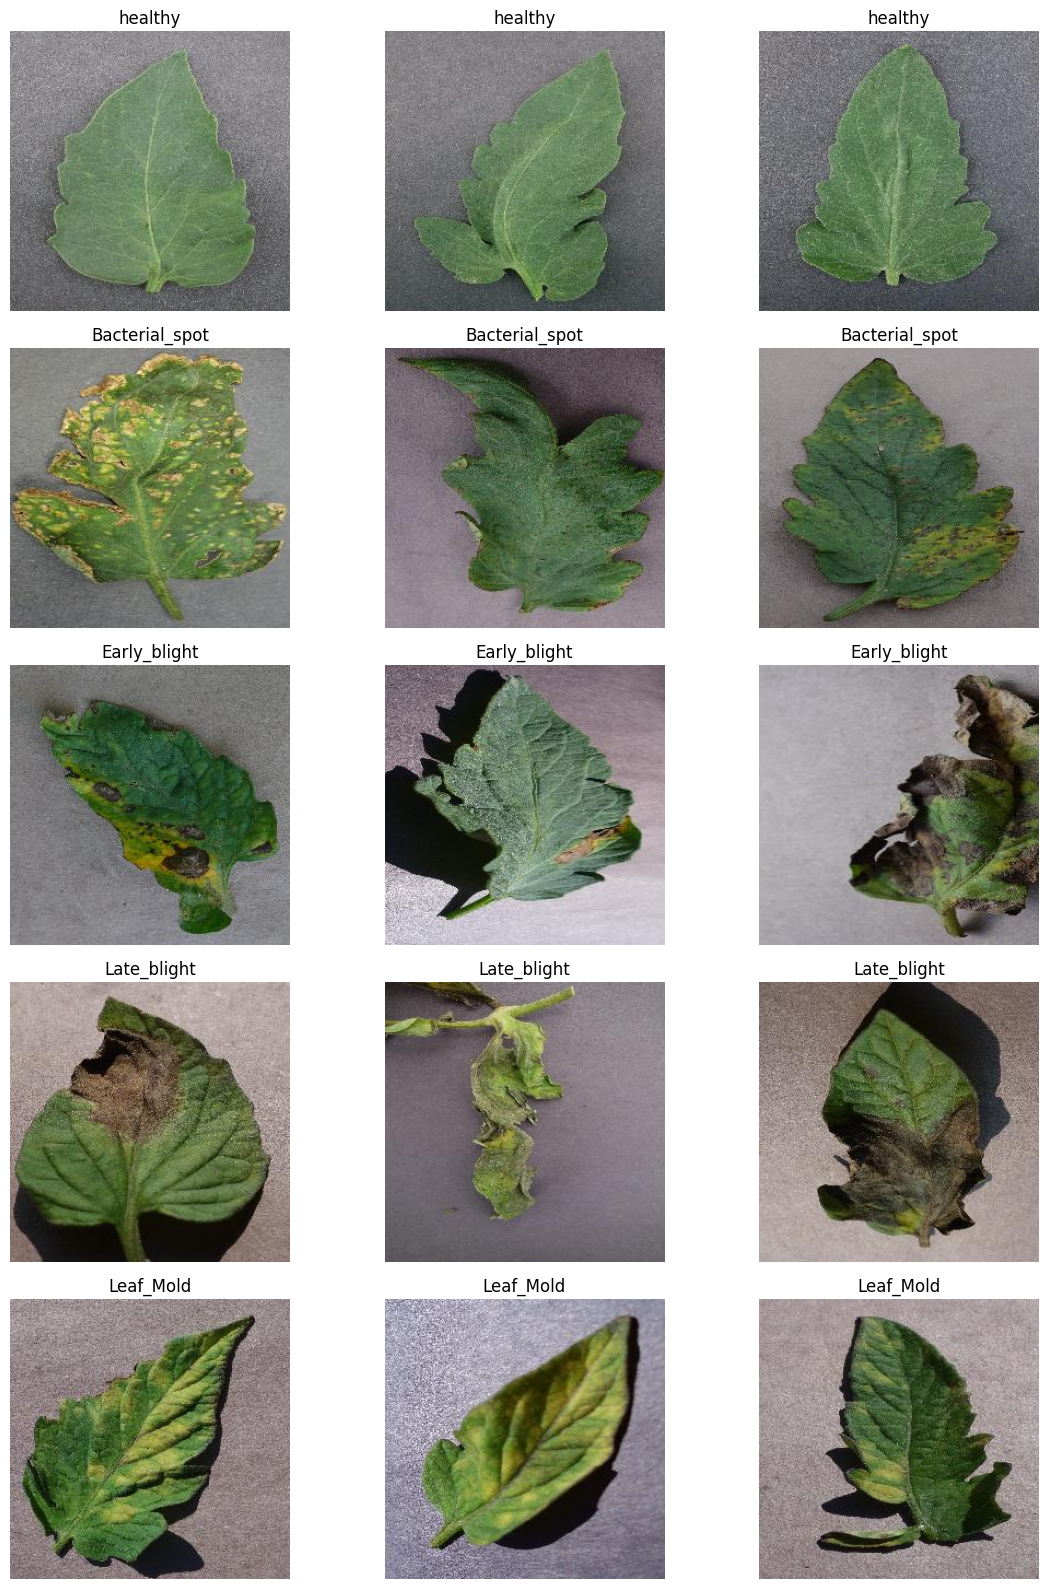

In [7]:
import random
from PIL import Image

random.seed(42)

fig, axes = plt.subplots(5, 3, figsize=(12, 16))

for row, class_name in enumerate(selected_classes):

    folder_path = selected_data[class_name]

    images = [
        file for file in folder_path.iterdir()
        if file.suffix.lower() in image_extensions
    ]

    sample_images = random.sample(images, min(3, len(images)))

    for col, image_path in enumerate(sample_images):

        img = Image.open(image_path)

        axes[row, col].imshow(img)
        axes[row, col].set_title(class_name.replace("Tomato___", ""))
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [8]:
from PIL import Image
from collections import Counter

image_sizes = []

for class_name in selected_classes:
    folder_path = selected_data[class_name]

    images = [
        file for file in folder_path.iterdir()
        if file.suffix.lower() in image_extensions
    ]

    for image_path in images[:50]:
        with Image.open(image_path) as img:
            image_sizes.append(img.size)

# Display common image dimensions
size_counts = Counter(image_sizes)

print("Most common image dimensions:\n")

for size, count in size_counts.most_common(10):
    print(f"{size}: {count} images")

Most common image dimensions:

(256, 256): 250 images


In [9]:
# Display details of one sample image

sample_folder = selected_data["Tomato___healthy"]

sample_image_path = next(
    file for file in sample_folder.iterdir()
    if file.suffix.lower() in image_extensions
)

with Image.open(sample_image_path) as img:
    print("Image format:", img.format)
    print("Image dimensions:", img.size)
    print("Image mode:", img.mode)

Image format: JPEG
Image dimensions: (256, 256)
Image mode: RGB


In [10]:
from sklearn.model_selection import train_test_split
from pathlib import Path
import pandas as pd

In [11]:
# Store image paths and their corresponding labels

image_data = []

for class_name in selected_classes:

    folder_path = selected_data[class_name]

    for image_path in folder_path.iterdir():

        if image_path.suffix.lower() in image_extensions:

            image_data.append({
                "image_path": str(image_path),
                "label": class_name
            })

# Create DataFrame
df_images = pd.DataFrame(image_data)

print("Total images:", len(df_images))
print("\nImages per category:")
print(df_images["label"].value_counts())

Total images: 7579

Images per category:
label
Tomato___Bacterial_spot    2127
Tomato___Late_blight       1909
Tomato___healthy           1591
Tomato___Early_blight      1000
Tomato___Leaf_Mold          952
Name: count, dtype: int64


In [12]:
# First split: 70% training and 30% temporary

train_df, temp_df = train_test_split(
    df_images,
    test_size=0.30,
    random_state=42,
    stratify=df_images["label"]
)

# Second split: Divide remaining 30% equally
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nTotal images:", len(train_df) + len(val_df) + len(test_df))

Training images: 5305
Validation images: 1137
Testing images: 1137

Total images: 7579


In [13]:
split_summary = pd.DataFrame({
    "Training": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Testing": test_df["label"].value_counts()
})

print(split_summary)

                         Training  Validation  Testing
label                                                 
Tomato___Bacterial_spot      1489         319      319
Tomato___Late_blight         1336         286      287
Tomato___healthy             1114         239      238
Tomato___Early_blight         700         150      150
Tomato___Leaf_Mold            666         143      143


In [14]:
import tensorflow as tf

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: []


In [15]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image size: (224, 224)
Batch size: 16


In [16]:
def load_and_preprocess_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMG_SIZE)

    image = preprocess_input(image)

    return image, label

In [17]:
class_names = selected_classes

class_to_index = {
    name: index for index, name in enumerate(class_names)
}

print(class_to_index)

{'Tomato___healthy': 0, 'Tomato___Bacterial_spot': 1, 'Tomato___Early_blight': 2, 'Tomato___Late_blight': 3, 'Tomato___Leaf_Mold': 4}


In [18]:
# Convert category names into numerical labels

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["label_id"] = train_df["label"].map(class_to_index)
val_df["label_id"] = val_df["label"].map(class_to_index)
test_df["label_id"] = test_df["label"].map(class_to_index)

print(train_df.head())

                                             image_path  \
3857  C:\Users\ABHAY YADAV\OneDrive\Desktop\ghub\pla...   
1941  C:\Users\ABHAY YADAV\OneDrive\Desktop\ghub\pla...   
1135  C:\Users\ABHAY YADAV\OneDrive\Desktop\ghub\pla...   
7487  C:\Users\ABHAY YADAV\OneDrive\Desktop\ghub\pla...   
3742  C:\Users\ABHAY YADAV\OneDrive\Desktop\ghub\pla...   

                        label  label_id  
3857    Tomato___Early_blight         2  
1941  Tomato___Bacterial_spot         1  
1135         Tomato___healthy         0  
7487       Tomato___Leaf_Mold         4  
3742    Tomato___Early_blight         2  


In [19]:
def create_dataset(dataframe, shuffle=False):

    image_paths = dataframe["image_path"].values
    labels = dataframe["label_id"].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED
        )

    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

In [20]:
train_dataset = create_dataset(train_df, shuffle=True)

val_dataset = create_dataset(val_df)

test_dataset = create_dataset(test_df)

print("TensorFlow datasets created successfully!")

TensorFlow datasets created successfully!


In [21]:
for images, labels in train_dataset.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)
Minimum pixel value: -1.0
Maximum pixel value: 0.93401563


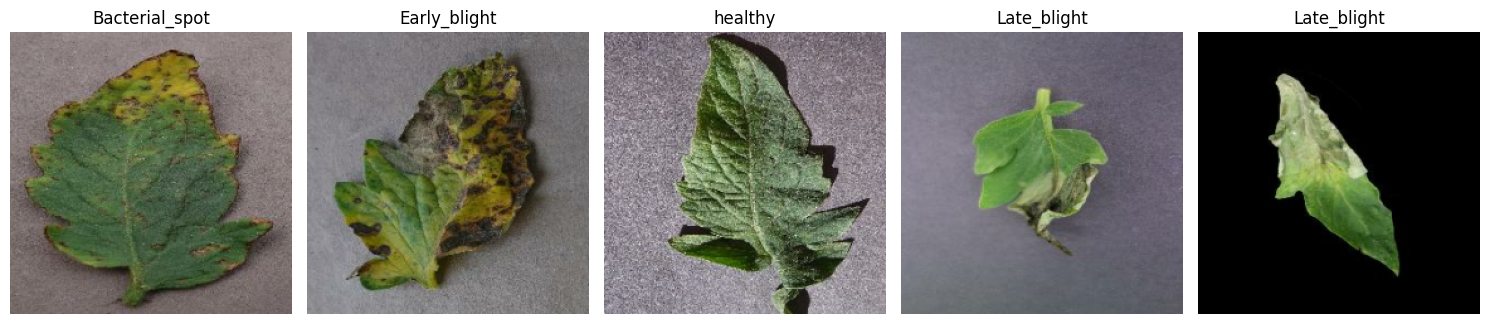

In [22]:
# Get one batch of training images
for images, labels in train_dataset.take(1):
    sample_images = images.numpy()
    sample_labels = labels.numpy()

# Convert pixel values back for display
display_images = (sample_images + 1.0) / 2.0

# Display 5 images
plt.figure(figsize=(15, 6))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(display_images[i])
    plt.title(class_names[sample_labels[i]].replace("Tomato___", ""))
    plt.axis("off")

plt.tight_layout()
plt.show()